<a href="https://colab.research.google.com/github/Yileidy-rg/Examen_INFO_ApNegocios/blob/main/Colab_Corte3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Corte 3 — Machine Learning e integración final
## Caso 03: Solicitud y aprobación de créditos

**Integrantes:**

Meylin Iliana López Solera

Yileidy Rivera Granados.

En este corte vamos a intentar predecir si una solicitud de crédito será aprobada o rechazada, como propusimos en el Corte 1. Además, vamos a estudiar si podemos anticipar cuáles solicitudes van a necesitar información adicional, porque en el Corte 2 encontramos que esa parte del proceso puede causar demoras.

## 1. Configurar el entorno y leer los datos
Primero abrimos el archivo de solicitudes de crédito que tenemos en GitHub. Con este código podemos ver cuántos registros hay y qué información contiene el archivo.

In [1]:
from pathlib import Path
import subprocess
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import unicodedata

ROOT = Path('/content/repo')
REPO_URL = 'https://github.com/Yileidy-rg/Examen_INFO_ApNegocios.git'
if not (ROOT / '.git').exists():
    subprocess.run(['git', 'clone', '--depth', '1', REPO_URL, str(ROOT)], check=True)

ruta = ROOT / 'datos' / 'raw' / 'caso_03_creditos.csv'
assert ruta.exists(), f'No se encontró el CSV en {ruta}. Verifica que el repositorio sea accesible.'
df = pd.read_csv(ruta)
print('Eventos:', len(df), '| Solicitudes:', df['case_id'].nunique())
print('Columnas:', df.columns.tolist())
display(df.head())

Eventos: 7978 | Solicitudes: 1200
Columnas: ['case_id', 'activity', 'timestamp', 'resource', 'tipo_credito', 'monto_solicitado', 'ingreso_mensual', 'nivel_endeudamiento', 'antiguedad_laboral_meses', 'canal', 'edad_solicitante']


,case_id,activity,timestamp,resource,tipo_credito,monto_solicitado,ingreso_mensual,nivel_endeudamiento,antiguedad_laboral_meses,canal,edad_solicitante
0,SOL00201,Solicitud recibida,2026-01-05 07:29:11,Ejecutivo_02,Vehicular,13600.0,4248.69,0.32,81,Sucursal,40
1,SOL00781,Solicitud recibida,2026-01-05 10:45:17,Ejecutivo_06,Personal,17000.0,1330.61,0.09,14,Sucursal,48
2,SOL00909,Solicitud recibida,2026-01-05 11:37:47,Ejecutivo_04,Personal,11600.0,1899.40,0.02,136,Sucursal,45
3,SOL00954,Solicitud recibida,2026-01-05 12:28:16,Ejecutivo_06,Consumo,2300.0,2402.15,0.51,53,Sucursal,31
4,SOL00014,Solicitud recibida,2026-01-05 12:54:56,Sistema,Consumo,3900.0,1087.15,0.37,59,Web,59


## 2. Limpieza y revisión de calidad
Algunas actividades pueden estar escritas de formas distintas, por ejemplo, con tildes o mayúsculas. Las dejamos con un mismo formato para poder contarlas correctamente. También revisamos las fechas y si hay datos que cambian dentro de una misma solicitud.

In [2]:
def normalizar(valor):
    if pd.isna(valor):
        return ''
    texto = ' '.join(str(valor).strip().lower().split())
    return ''.join(c for c in unicodedata.normalize('NFKD', texto)
                   if not unicodedata.combining(c))

datos = df.copy()
datos['activity_normalizada'] = datos['activity'].apply(normalizar)
datos['timestamp'] = pd.to_datetime(datos['timestamp'], errors='coerce')
datos['_orden_original'] = np.arange(len(datos))
datos = datos.sort_values(['case_id', 'timestamp', '_orden_original'], kind='stable', na_position='last')
print('Fechas faltantes:', datos['timestamp'].isna().sum())
print('Actividades normalizadas:')
display(datos['activity_normalizada'].value_counts().to_frame('eventos'))

Fechas faltantes: 14
Actividades normalizadas:


,eventos
activity_normalizada,
verificacion de documentos,1533
solicitud recibida,1206
analisis financiero,1149
aprobacion,868
formalizacion,866
desembolso,866
solicitud de informacion adicional,365
recepcion de informacion,327
rechazo,298


## 3. Construir datos por solicitud y clasificar el resultado final
En el archivo original, una solicitud aparece varias veces porque pasa por distintas actividades. Para entrenar los modelos necesitamos una sola fila por solicitud. Por eso reunimos la información de cada crédito y revisamos si terminó aprobado, rechazado o desistido.
Si una solicitud tiene resultados contradictorios o no tiene una decisión clara, la dejamos aparte. Usamos los datos registrados al principio del trámite, para no darle al modelo información de cosas que todavía no habían pasado.

In [3]:
numericas = ['monto_solicitado', 'ingreso_mensual', 'nivel_endeudamiento',
             'antiguedad_laboral_meses', 'edad_solicitante']
categoricas = ['tipo_credito', 'canal']
columnas = numericas + categoricas
assert set(columnas).issubset(datos.columns), f'Faltan columnas: {set(columnas)-set(datos.columns)}'

# Elegir la fila inicial (y no groupby.first(), que puede mezclar filas si hay nulos)
inicio = datos.drop_duplicates('case_id', keep='first').set_index('case_id')[columnas]
variaciones = datos.groupby('case_id')[columnas].nunique(dropna=True)
print('Casos con atributos que cambian entre eventos:')
display((variaciones > 1).sum().to_frame('n_casos'))

actividades_caso = datos.groupby('case_id')['activity_normalizada'].agg(set)
print('Actividades que contienen términos relacionados con decisiones:')
print(sorted(a for a in datos['activity_normalizada'].unique()
             if any(t in a for t in ('aprob', 'rechaz', 'desist', 'informacion adicional'))))

# Estas etiquetas reflejan los nombres que se usaron en el Corte 2.
# Si la lista anterior evidencia otra denominación, ajustar aquí y documentarlo.
EVENTOS_APROBACION = {'aprobacion'}
EVENTOS_RECHAZO = {'rechazo'}
EVENTOS_DESISTIMIENTO = {'desistimiento'}
EVENTOS_INFO = {'solicitud de informacion adicional'}

def decision(actividades):
    a = bool(actividades & EVENTOS_APROBACION)
    r = bool(actividades & EVENTOS_RECHAZO)
    d = bool(actividades & EVENTOS_DESISTIMIENTO)
    if sum([a, r, d]) > 1: return 'Ambiguo'
    if a: return 'Aprobada'
    if r: return 'Rechazada'
    if d: return 'Desistida'
    return 'Sin decisión'

resumen = inicio.copy()
resumen['resultado'] = actividades_caso.map(decision)
resumen['necesita_info'] = actividades_caso.apply(lambda acts: int(bool(acts & EVENTOS_INFO)))
print('Distribución de decisiones:')
display(resumen['resultado'].value_counts(dropna=False).to_frame('solicitudes'))
print('Registro de información adicional:', resumen['necesita_info'].value_counts().to_dict())

Casos con atributos que cambian entre eventos:


,n_casos
monto_solicitado,0
ingreso_mensual,0
nivel_endeudamiento,0
antiguedad_laboral_meses,0
edad_solicitante,0
tipo_credito,0
canal,0


Actividades que contienen términos relacionados con decisiones:
['aprobacion', 'desistimiento', 'rechazo', 'solicitud de informacion adicional']
Distribución de decisiones:


,solicitudes
resultado,
Aprobada,864
Rechazada,298
Desistida,37
Sin decisión,1


Registro de información adicional: {0: 892, 1: 308}


## 4. Predicción principal: aprobación o rechazo
Queremos que el modelo intente reconocer a partir de los datos iniciales del crédito y del solicitante, si una solicitud terminará aprobada o rechazada.
Usamos 1 para aprobada y 0 para rechazada. No contamos los desistimientos como rechazos. El resultado real sirve para enseñarle al modelo, pero no se incluye entre los datos que usa para predecir.

In [4]:
principal = resumen[resumen['resultado'].isin(['Aprobada', 'Rechazada'])].copy()
principal['aprobada'] = (principal['resultado'] == 'Aprobada').astype(int)
X_principal = principal[columnas].copy()
y_principal = principal['aprobada']
print('Casos para aprobación/rechazo:', len(principal))
print('Clases: 0 = Rechazada; 1 = Aprobada')
display(pd.DataFrame({'cantidad': y_principal.value_counts().sort_index(),
                      'porcentaje': (y_principal.value_counts(normalize=True).sort_index()*100).round(2)}))
print('Valores ausentes en X:')
display(X_principal.isna().sum().to_frame('nulos'))
assert y_principal.nunique() == 2, 'El modelo requiere casos tanto aprobados como rechazados.'
assert y_principal.value_counts().min() >= 5, 'Muy pocos casos de una clase para 5 particiones; revisar datos.'

Casos para aprobación/rechazo: 1162
Clases: 0 = Rechazada; 1 = Aprobada


,cantidad,porcentaje
aprobada,,
0,298,25.65
1,864,74.35


Valores ausentes en X:


,nulos
monto_solicitado,0
ingreso_mensual,0
nivel_endeudamiento,0
antiguedad_laboral_meses,0
edad_solicitante,0
tipo_credito,0
canal,0


## 5. Preparar y entrenar los modelos
Separamos las solicitudes: 80 % para que los modelos aprendan y 20 % para comprobar cómo les va con casos que no han visto. También preparamos las columnas numéricas y las que contienen palabras, como el tipo de crédito.
Probamos tres modelos: uno básico que sirve de comparación (DummyClassifier), Regresión logística y Random Forest. Después comparamos cuántas predicciones hacen bien y qué tipos de errores cometen.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance


def crear_preprocesador():
    return ColumnTransformer([
        ('num', Pipeline([('imputar', SimpleImputer(strategy='median')),
                          ('escalar', StandardScaler())]), numericas),
        ('cat', Pipeline([('imputar', SimpleImputer(strategy='most_frequent')),
                          ('codificar', OneHotEncoder(handle_unknown='ignore'))]), categoricas)
    ])

def evaluar_objetivo(X, y, titulo):
    assert X.index.is_unique, 'Debe haber una fila por solicitud.'
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.20, random_state=42, stratify=y)
    print(f'{titulo}: entrenamiento={len(X_tr)}, prueba={len(X_te)}')
    definiciones = {
        'Modelo base': DummyClassifier(strategy='most_frequent'),
        'Regresión logística': LogisticRegression(max_iter=1000, random_state=42),
        'Random Forest': RandomForestClassifier(n_estimators=200, min_samples_leaf=3,
                                                 random_state=42)
    }
    modelos_ajustados, filas = {}, []
    for nombre, estimador in definiciones.items():
        modelo = Pipeline([('preprocesador', crear_preprocesador()),
                           ('modelo', estimador)])
        modelo.fit(X_tr, y_tr)
        pred = modelo.predict(X_te)
        modelos_ajustados[nombre] = modelo
        filas.append({'Modelo': nombre,
                      'Accuracy': accuracy_score(y_te, pred),
                      'Precision': precision_score(y_te, pred, zero_division=0),
                      'Recall': recall_score(y_te, pred, zero_division=0),
                      'F1-score': f1_score(y_te, pred, zero_division=0)})
    resultados = pd.DataFrame(filas)
    display(resultados.round(3))
    resultados.set_index('Modelo')[['Precision', 'Recall', 'F1-score']].plot(
        kind='bar', figsize=(9, 4), ylim=(0, 1), rot=0,
        title=f'{titulo} — Comparación de modelos')
    plt.ylabel('Puntuación'); plt.tight_layout(); plt.show()
    return {'X_train': X_tr, 'X_test': X_te, 'y_train': y_tr, 'y_test': y_te,
            'modelos': modelos_ajustados, 'comparacion': resultados}

def detalle_modelo(experimento, nombre='Random Forest', titulo=''):
    modelo = experimento['modelos'][nombre]
    y_te, X_te = experimento['y_test'], experimento['X_test']
    pred = modelo.predict(X_te)
    print(classification_report(y_te, pred, labels=[0, 1], zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_te, pred, labels=[0, 1], cmap='Blues')
    plt.title(f'{titulo} — {nombre}'); plt.tight_layout(); plt.show()
    return modelo

## 6. Resultados de aprobación y rechazo
Aquí comparamos los tres modelos para ver cuál predice mejor el resultado de un crédito. No nos fijamos solamente en cuántas respuestas acierta en total, sino también en cuántas aprobaciones logra identificar y cuántas se le escapan.
La matriz de confusión nos ayuda a ver los aciertos y los errores de Random Forest. Más adelante vamos a explicar qué significan los números que obtengamos.

Aprobación o rechazo: entrenamiento=929, prueba=233


,Modelo,Accuracy,Precision,Recall,F1-score
0,Modelo base,0.742,0.742,1.000,0.852
1,Regresión logística,0.773,0.800,0.925,0.858
2,Random Forest,0.777,0.804,0.925,0.860


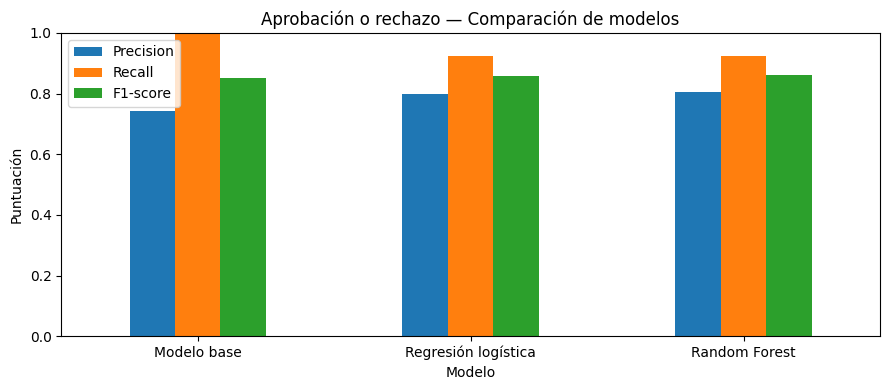

              precision    recall  f1-score   support

           0       0.62      0.35      0.45        60
           1       0.80      0.92      0.86       173

    accuracy                           0.78       233
   macro avg       0.71      0.64      0.65       233
weighted avg       0.76      0.78      0.75       233



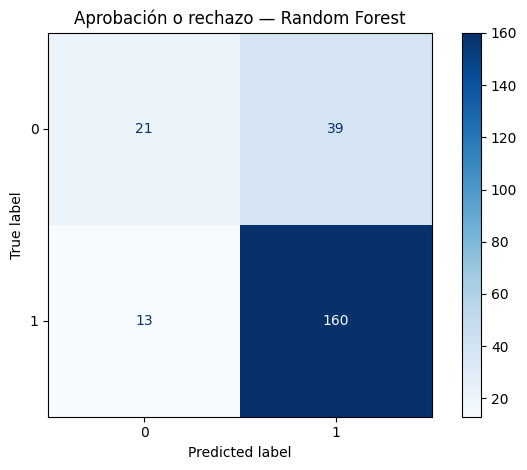

In [6]:
exp_principal = evaluar_objetivo(X_principal, y_principal, 'Aprobación o rechazo')
modelo_principal_rf = detalle_modelo(exp_principal, 'Random Forest', 'Aprobación o rechazo')

## 7. ¿Qué datos ayudan más a predecir la aprobación?
En esta parte revisamos cuáles características parecen ayudar más a Random Forest, por ejemplo, los ingresos, el monto solicitado o el tipo de crédito.
El código desordena una columna a la vez y observa si el modelo empeora o mejora. Si aparece un número negativo, no significa que el dato esté mal: puede ser que en esta prueba no esté ayudando mucho. Esto tampoco demuestra que una variable sea la causa de una aprobación o un rechazo.

,Variable,Importancia_media,Desviacion
2,nivel_endeudamiento,0.0344,0.0117
0,monto_solicitado,0.0105,0.0120
1,ingreso_mensual,0.0054,0.0066
3,antiguedad_laboral_meses,0.0031,0.0080
5,tipo_credito,0.0000,0.0053
6,canal,-0.0004,0.0043
4,edad_solicitante,-0.0030,0.0055


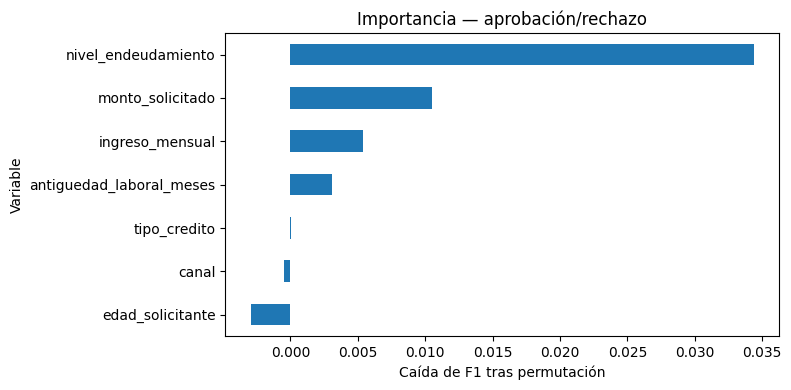

In [7]:
imp_principal = permutation_importance(
    modelo_principal_rf, exp_principal['X_test'], exp_principal['y_test'],
    n_repeats=10, random_state=42, scoring='f1')
imp_tabla_principal = pd.DataFrame({
    'Variable': columnas,
    'Importancia_media': imp_principal.importances_mean,
    'Desviacion': imp_principal.importances_std
}).sort_values('Importancia_media', ascending=False)
display(imp_tabla_principal.round(4))
imp_tabla_principal.sort_values('Importancia_media').plot.barh(
    x='Variable', y='Importancia_media', legend=False, figsize=(8, 4))
plt.xlabel('Caída de F1 tras permutación'); plt.title('Importancia — aprobación/rechazo')
plt.tight_layout(); plt.show()

---
# Análisis adicional: ¿se necesitará más información?
En el Corte 2 encontramos que pedir y recibir documentos adicionales puede retrasar las solicitudes. Por eso quisimos probar una segunda predicción: identificar desde el principio cuáles créditos podrían necesitar más información.

En este análisis usamos 1 si se pidió información adicional y 0 si no se pidió. Trabajamos con solicitudes que ya tienen un resultado claro, para no confundir un trámite abierto con uno que nunca necesitó documentos extra.

Esta predicción es un complemento basado en un hallazgo de interés.

Casos elegibles: 1199


,cantidad,porcentaje
necesita_info,,
0,892,74.4
1,307,25.6


Información adicional: entrenamiento=959, prueba=240


,Modelo,Accuracy,Precision,Recall,F1-score
0,Modelo base,0.746,0.000,0.000,0.000
1,Regresión logística,0.725,0.273,0.049,0.083
2,Random Forest,0.708,0.333,0.148,0.205


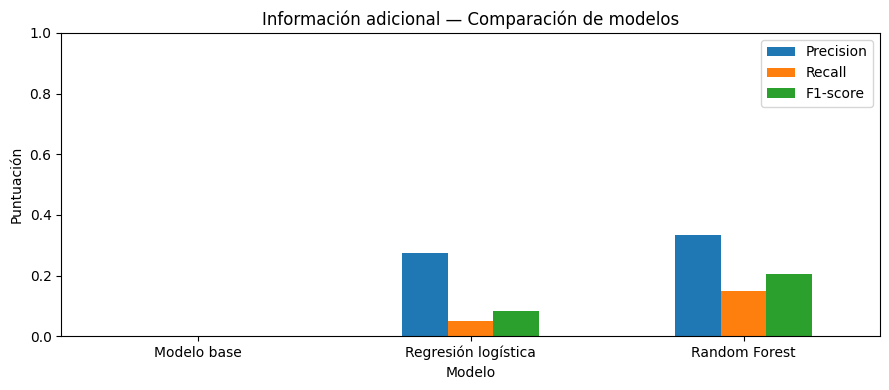

              precision    recall  f1-score   support

           0       0.76      0.90      0.82       179
           1       0.33      0.15      0.20        61

    accuracy                           0.71       240
   macro avg       0.54      0.52      0.51       240
weighted avg       0.65      0.71      0.66       240



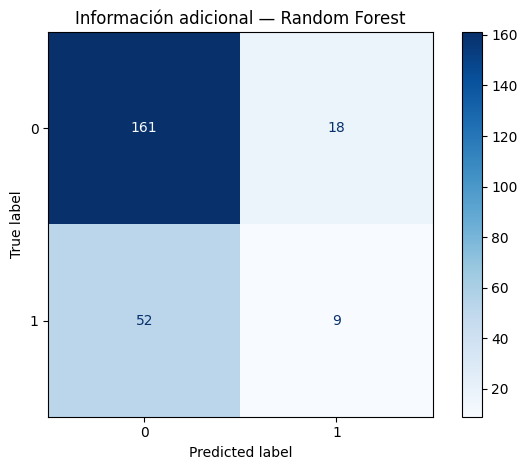

In [8]:
secundario = resumen[resumen['resultado'].isin(['Aprobada', 'Rechazada', 'Desistida'])].copy()
X_info = secundario[columnas].copy()
y_info = secundario['necesita_info'].astype(int)
print('Casos elegibles:', len(secundario))
display(pd.DataFrame({'cantidad': y_info.value_counts().sort_index(),
                     'porcentaje': (y_info.value_counts(normalize=True).sort_index()*100).round(2)}))
assert y_info.nunique() == 2, 'Faltan casos positivos o negativos para información adicional.'
exp_info = evaluar_objetivo(X_info, y_info, 'Información adicional')
modelo_info_rf = detalle_modelo(exp_info, 'Random Forest', 'Información adicional')

## ¿Qué datos ayudan más a predecir información adicional?
Ahora revisamos cuáles características parecen ser más útiles para anticipar si el banco tendrá que pedir otros documentos. Usamos la misma forma de calcular la importancia que en el modelo principal.

Los resultados pueden cambiar un poco con respecto al Colab anterior porque en esta versión revisamos con más cuidado qué solicitudes y datos iniciales utilizamos.

,Variable,Importancia_media,Desviacion
6,canal,0.0978,0.0416
5,tipo_credito,0.0238,0.0416
1,ingreso_mensual,0.0129,0.0536
0,monto_solicitado,0.0115,0.0257
2,nivel_endeudamiento,-0.0176,0.0275
3,antiguedad_laboral_meses,-0.0203,0.0443
4,edad_solicitante,-0.0299,0.0415


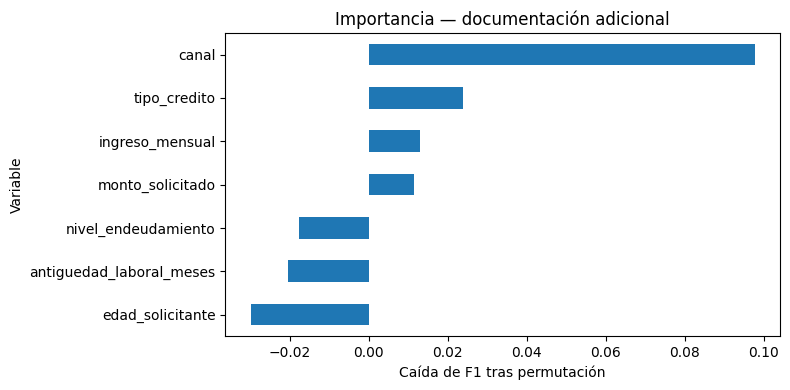

In [9]:
imp_info = permutation_importance(modelo_info_rf, exp_info['X_test'], exp_info['y_test'],
                                  n_repeats=10, random_state=42, scoring='f1')
imp_tabla_info = pd.DataFrame({'Variable': columnas,
                              'Importancia_media': imp_info.importances_mean,
                              'Desviacion': imp_info.importances_std}).sort_values('Importancia_media', ascending=False)
display(imp_tabla_info.round(4))
imp_tabla_info.sort_values('Importancia_media').plot.barh(
    x='Variable', y='Importancia_media', figsize=(8, 4), legend=False)
plt.xlabel('Caída de F1 tras permutación'); plt.title('Importancia — documentación adicional')
plt.tight_layout(); plt.show()

## 9. Relación entre el resultado del crédito y los documentos extra
En esta tabla juntamos los dos temas del proyecto. Comparamos cuántas solicitudes aprobadas, rechazadas y desistidas necesitaron información adicional.

Queremos observar si hay diferencias entre esos grupos. Si vemos una relación, eso no significa que pedir documentos sea la causa de aprobar o rechazar un crédito: solamente estamos comparando lo que quedó registrado.

,No necesitó info,Sí necesitó info
resultado,,
Aprobada,665,199
Desistida,0,37
Rechazada,227,71


,No necesitó info,Sí necesitó info
Porcentaje dentro de cada resultado,,
Aprobada,77.0,23.0
Desistida,0.0,100.0
Rechazada,76.2,23.8


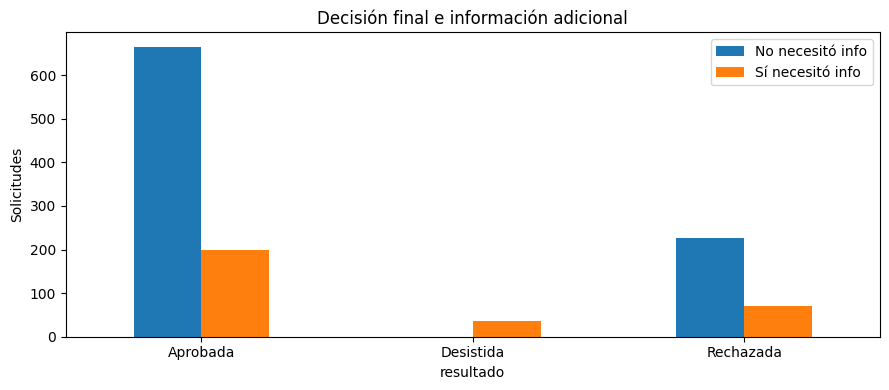

In [10]:
cruce = pd.crosstab(secundario['resultado'], secundario['necesita_info'])
cruce = cruce.reindex(columns=[0, 1], fill_value=0)
cruce.columns = ['No necesitó info', 'Sí necesitó info']
display(cruce)
display((cruce.div(cruce.sum(axis=1), axis=0)*100).round(1).rename_axis('Porcentaje dentro de cada resultado'))
cruce.plot(kind='bar', figsize=(9, 4), rot=0, title='Decisión final e información adicional')
plt.ylabel('Solicitudes'); plt.tight_layout(); plt.show()

## 10. Integración con Process Mining, limitaciones y recomendaciones

**¿Qué encontramos en el Corte 2?**

Mediante Process Mining estudiamos las actividades que siguen las solicitudes de crédito. Encontramos diferentes recorridos, revisiones adicionales y tiempos de espera. Uno de los hallazgos más importantes fue la solicitud de información adicional, ya que entre pedir y recibir estos documentos había una mediana de espera de 3,14 días.

**¿Cómo utilizamos esos hallazgos en Machine Learning?**

En el Corte 1 propusimos predecir la aprobación o el rechazo de créditos. Por eso, ese fue nuestro modelo principal.
Además, como en el Corte 2 encontramos retrasos relacionados con la documentación adicional, decidimos desarrollar un segundo modelo para intentar predecir cuáles solicitudes necesitarían más información.

**¿Qué variables del proceso utilizamos?**

Utilizamos siete características registradas en las solicitudes: monto, ingresos, endeudamiento, antigüedad laboral, edad, tipo de crédito y canal.
También utilizamos las actividades registradas en el proceso para identificar los resultados reales de cada solicitud y saber si necesitó información adicional.
Sin embargo, no usamos actividades posteriores como variables predictoras, porque queremos hacer las predicciones cuando se recibe la solicitud.

**¿Qué relación encontramos entre ambos análisis?**

El modelo principal logró predecir mejor las aprobaciones que los rechazos. Random Forest obtuvo un Accuracy de 77,7 %, pero solamente detectó alrededor del 35 % de los rechazos.
En el segundo modelo, Random Forest detectó el 14,8 % de las solicitudes que necesitaron información adicional.
También encontramos que el 23,0 % de las solicitudes aprobadas y el 23,8 % de las rechazadas necesitaron información adicional. Esto muestra que solicitar más documentos fue casi igual de frecuente en ambos grupos.

**¿Qué aporta cada técnica?**
Process Mining nos permitió conocer las actividades, los recorridos y los tiempos de espera del proceso.
Machine Learning nos permitió investigar si las características iniciales de una solicitud sirven para anticipar sus resultados.
Al combinar ambas técnicas, pudimos estudiar cómo funciona el proceso e investigar posibles formas de anticipar algunas situaciones. Sin embargo, los resultados todavía no son suficientes para recomendar que el banco utilice estos modelos de manera automática.


##11. Interpretación de los resultados

En el modelo de aprobación y rechazo, Random Forest obtuvo los mejores resultados generales, con un Accuracy de 77,7 % y un F1-score de 86,0 % para las aprobaciones.

Sin embargo, encontramos que el modelo tiene dificultades para identificar las solicitudes rechazadas. De las 60 solicitudes rechazadas en la prueba, detectó correctamente alrededor de 21.

La variable que mostró mayor importancia fue el nivel de endeudamiento, seguida por el monto solicitado.

En el modelo de información adicional, Random Forest obtuvo un F1-score de 20,5 % y solamente detectó 9 de las 61 solicitudes que realmente necesitaron documentación adicional.

Esto nos permitió concluir que los modelos pueden encontrar algunos patrones en los datos, pero todavía presentan errores importantes. Por lo tanto, consideramos que necesitan más pruebas y mejoras antes de utilizarse en una institución financiera.

##12. Conclusiones y recomendaciones

**Conclusiones**

El análisis de Process Mining permitió identificar diferentes recorridos y retrasos en las solicitudes de crédito, especialmente cuando se requiere información adicional.

El modelo principal logró superar ligeramente al modelo base. Sin embargo, aunque Random Forest obtuvo un Accuracy de 77,7 %, todavía presenta dificultades para identificar los rechazos.

La predicción de información adicional presentó resultados más bajos, con un Recall de 14,8 %. Esto indica que las características iniciales utilizadas no fueron suficientes para detectar la mayoría de estos casos.

La combinación de Process Mining y Machine Learning permitió comprender mejor el proceso y evaluar posibles mejoras, aunque no podemos afirmar que los modelos solucionen los retrasos.

**Recomendaciones**

Revisar los requisitos y documentos necesarios desde que el cliente presenta la solicitud. Esto podría ayudar a evitar que se solicite información adicional durante el trámite.

Mejorar el registro de información sobre documentos faltantes, revisiones y decisiones del crédito. Así se podrían desarrollar modelos predictivos con datos más completos.

Continuar evaluando los modelos con nuevas solicitudes, prestando especial atención a los rechazos y a los casos que necesitan información adicional antes de utilizarlos como apoyo en decisiones reales.